In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix)
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("Telco_Customer_Churn_Dataset .csv")
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print(df.shape)

(7043, 21)


In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
# Create a separate dataset for machine learning
model_df = df.copy()
columns_to_drop = [
    'customerID',
    'ChurnFlag',
    'TenureGroup',
    'TenureSegment',
    'ChargeSegment']
model_df = model_df.drop(
    columns=[
        col for col in columns_to_drop
        if col in model_df.columns ])
print("Model dataset shape:", model_df.shape)

Model dataset shape: (7043, 20)


In [7]:
# Features
X = model_df.drop(columns=['Churn'])
# Target
y = model_df['Churn'].map({
    'No': 0,
    'Yes': 1})
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)
Churn
0    5174
1    1869
Name: count, dtype: int64


In [8]:
print("Target distribution:")
print( y.value_counts(normalize=True) * 100)

Target distribution:
Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.20,
    random_state=42,
    stratify=y)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [10]:
categorical_columns = X.select_dtypes(
    include=['object']
).columns.tolist()
numerical_columns = X.select_dtypes(
    exclude=['object']
).columns.tolist()
print("Categorical columns:")
print(categorical_columns)
print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [11]:
preprocessor = ColumnTransformer(
    transformers=[( 'num',
            StandardScaler(),
            numerical_columns ), (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_columns) ])
print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [12]:
model = Pipeline(
    steps=[ (
            'preprocessor',
            preprocessor ), (
            'classifier',
            LogisticRegression(
                max_iter=1000 ))])
print("Logistic Regression model created successfully.")

Logistic Regression model created successfully.


In [13]:
model.fit(
    X_train,
    y_train)
print("Model training completed successfully!")

y_pred = model.predict(X_test)
print("Predictions generated successfully.")

y_probability = model.predict_proba(
    X_test)[:, 1]
print("Churn probabilities generated successfully.")

Model training completed successfully!
Predictions generated successfully.
Churn probabilities generated successfully.


In [14]:
accuracy = accuracy_score(
    y_test,
    y_pred)
print( f"Accuracy: {accuracy * 100:.2f}%")
precision = precision_score(
    y_test,
    y_pred)
print(f"Precision: {precision * 100:.2f}%")
recall = recall_score(
    y_test,
    y_pred)
print( f"Recall: {recall * 100:.2f}%")
f1 = f1_score(
    y_test,
    y_pred)
print(f"F1 Score: {f1 * 100:.2f}%")
roc_auc = roc_auc_score(
    y_test,
    y_probability)
print( f"ROC-AUC: {roc_auc:.3f}")

Accuracy: 80.55%
Precision: 65.72%
Recall: 55.88%
F1 Score: 60.40%
ROC-AUC: 0.842


In [15]:
results_percentage = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC' ],
    'Score': [
        f'{accuracy * 100:.2f}%',
        f'{precision * 100:.2f}%',
        f'{recall * 100:.2f}%',
        f'{f1 * 100:.2f}%',
        f'{roc_auc:.3f}']})
results_percentage

,Metric,Score
0,Accuracy,80.55%
1,Precision,65.72%
2,Recall,55.88%
3,F1 Score,60.40%
4,ROC-AUC,0.842


In [16]:
print( classification_report(
        y_test,
        y_pred,
        target_names=[
            'No Churn',
            'Churn' ] ))

              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [17]:
cm = confusion_matrix(
    y_test,
    y_pred)
print(cm)

[[926 109]
 [165 209]]


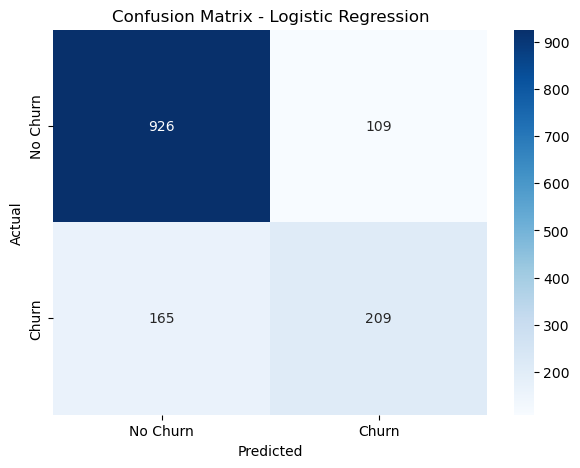

In [18]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        'No Churn',
        'Churn'],
    yticklabels=[
        'No Churn',
        'Churn' ])
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [19]:
tn, fp, fn, tp = cm.ravel()
print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

True Negatives : 926
False Positives: 109
False Negatives: 165
True Positives : 209


In [21]:
prediction_results = X_test.copy()
prediction_results['Actual_Churn'] = y_test.values
prediction_results['Predicted_Churn'] = y_pred
prediction_results['Churn_Probability'] = y_probability
prediction_results.head(5)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0,0,0.045920
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,1,0.683713
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,0,0,0.058940
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,No,Electronic check,78.20,1468.75,0,0,0.401835
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0,0,0.021424


In [22]:
prediction_results = X_test.copy()
prediction_results.insert( 0,
    'customerID',
    df.loc[X_test.index, 'customerID'])
prediction_results['Actual_Churn'] = y_test.values
prediction_results['Predicted_Churn'] = y_pred
prediction_results['Churn_Probability'] = y_probability
prediction_results.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability
437,4376-KFVRS,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0,0,0.045920
2280,2754-SDJRD,Female,1,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,1,0.683713
2235,9917-KWRBE,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,...,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,0,0,0.058940
4460,0365-GXEZS,Male,0,Yes,No,18,Yes,No,Fiber optic,No,...,No,No,Month-to-month,No,Electronic check,78.20,1468.75,0,0,0.401835
3761,9385-NXKDA,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0,0,0.021424


In [23]:
high_probability_customers = (
    prediction_results
    .sort_values(
        'Churn_Probability',
        ascending=False ))
high_probability_customers[ [
        'customerID',
        'Actual_Churn',
        'Predicted_Churn',
        'Churn_Probability']].head(5)

,customerID,Actual_Churn,Predicted_Churn,Churn_Probability
3380,5178-LMXOP,1,1,0.854280
6866,0295-PPHDO,1,1,0.831583
2631,6861-XWTWQ,1,1,0.828147
6365,8884-ADFVN,1,1,0.821692
4585,1069-XAIEM,1,1,0.818493


In [25]:
def risk_category(probability):
    if probability >= 0.70:
        return 'High Risk'
    elif probability >= 0.40:
        return 'Medium Risk'
    else:
        return 'Low Risk'

prediction_results['RiskCategory'] = (
    prediction_results['Churn_Probability']
    .apply(risk_category))
prediction_results[ [
        'customerID',
        'Actual_Churn',
        'Predicted_Churn',
        'Churn_Probability',
        'RiskCategory']].head(10)

,customerID,Actual_Churn,Predicted_Churn,Churn_Probability,RiskCategory
437,4376-KFVRS,0,0,0.045920,Low Risk
2280,2754-SDJRD,0,1,0.683713,Medium Risk
2235,9917-KWRBE,0,0,0.058940,Low Risk
4460,0365-GXEZS,0,0,0.401835,Medium Risk
3761,9385-NXKDA,0,0,0.021424,Low Risk
5748,4686-UXDML,0,1,0.602978,Medium Risk
3568,2227-JRSJX,0,0,0.447629,Medium Risk
2976,4830-FAXFM,0,0,0.130336,Low Risk
5928,1830-IPXVJ,0,0,0.002804,Low Risk
1639,4690-LLKUA,1,0,0.394739,Low Risk


RiskCategory
Low Risk       969
Medium Risk    347
High Risk       93
Name: count, dtype: int64


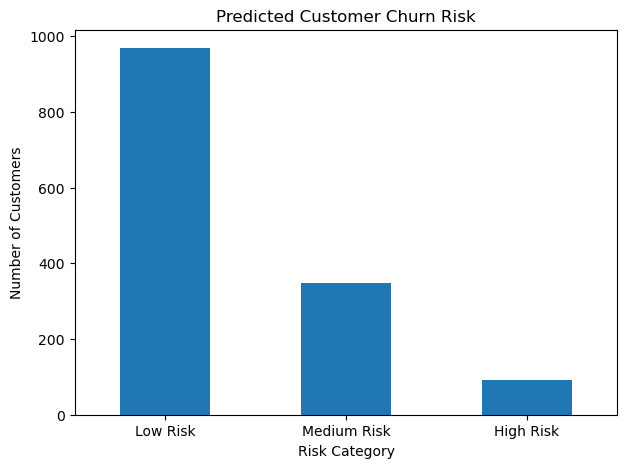

In [26]:
risk_counts = (
    prediction_results['RiskCategory']
    .value_counts()
    .reindex([
        'Low Risk',
        'Medium Risk',
        'High Risk']))
print(risk_counts)

plt.figure(figsize=(7, 5))
risk_counts.plot(kind='bar')
plt.title('Predicted Customer Churn Risk')
plt.xlabel('Risk Category')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

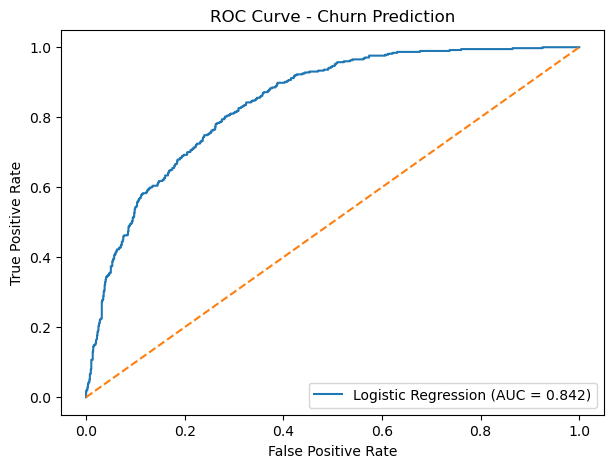

In [27]:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability)
plt.figure(figsize=(7, 5))
plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.3f})')
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--')
plt.title('ROC Curve - Churn Prediction')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

In [28]:
final_model_results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC' ],
    'Value': [
        round(accuracy, 4),
        round(precision, 4),
        round(recall, 4),
        round(f1, 4),
        round(roc_auc, 4)]})
final_model_results

,Metric,Value
0,Accuracy,0.8055
1,Precision,0.6572
2,Recall,0.5588
3,F1 Score,0.6040
4,ROC-AUC,0.8421
